# Industrial Failure Intelligence — Análisis exploratorio

Notebook del proyecto sobre el dataset **AI4I 2020 Predictive Maintenance Dataset** (UCI, CC BY 4.0), sintético.

Reutiliza los módulos de `src/` y los artefactos generados por `python -m src.pipeline`. Para regenerar todo desde cero: ejecuta primero el pipeline.


In [1]:
import sys
from pathlib import Path

# Permite ejecutar el notebook desde cualquier ubicación
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config
from src.preprocessing import failure_rate_summary, load_data, validate_data

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

## 1. Carga y calidad de datos

In [2]:
df = load_data()
checks = validate_data(df)
summary = failure_rate_summary(df)

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Valores faltantes: {checks['missing_values_total']}")
print(f"Duplicados: {checks['duplicate_rows']}")
print(f"Fallas: {summary['n_failures']} ({summary['failure_rate_pct']}%)")
df.head()

Dimensiones: 10000 filas x 14 columnas
Valores faltantes: 0
Duplicados: 0
Fallas: 339 (3.39%)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


La variable objetivo está fuertemente desbalanceada: **3.39%** de fallas.
Eso hace que el accuracy sea una métrica poco informativa (un clasificador trivial
que nunca predice falla alcanzaría ~96.6%).
A continuación, la distribución de fallas por tipo de máquina (L, M, H).

In [3]:
by_type = df.groupby("Type")[config.TARGET].agg(["sum", "count"])
by_type["tasa_falla_pct"] = 100 * by_type["sum"] / by_type["count"]
by_type

,sum,count,tasa_falla_pct
Type,,,
H,21,1003,2.093719
L,235,6000,3.916667
M,83,2997,2.769436


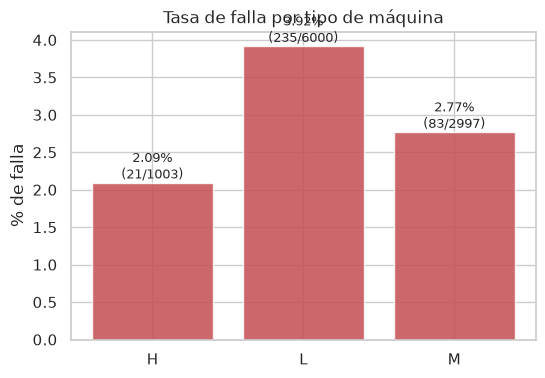

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(by_type.index, by_type["tasa_falla_pct"], color="#c44e52", alpha=0.85)
for bar, (typ, row) in zip(bars, by_type.iterrows()):
    ax.annotate(f"{row['tasa_falla_pct']:.2f}%\n({int(row['sum'])}/{int(row['count'])})",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Tasa de falla por tipo de máquina")
ax.set_ylabel("% de falla")
plt.show()

## 2. Distribuciones de variables operativas

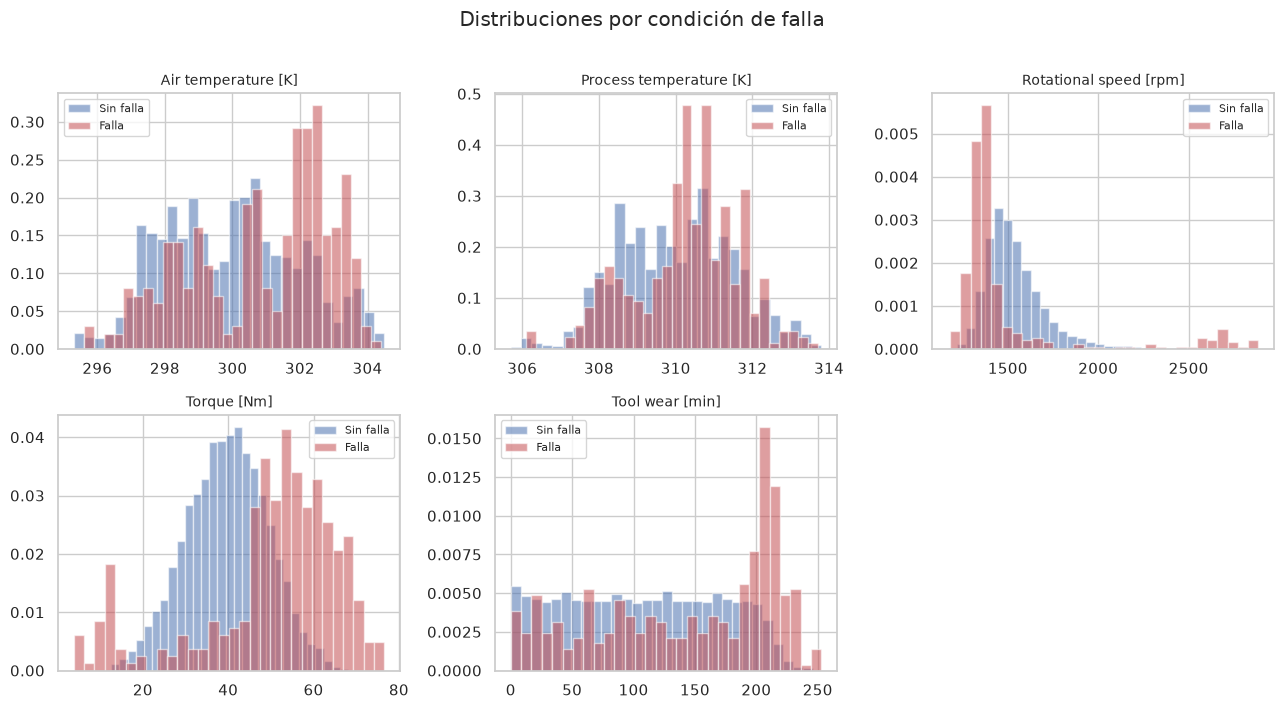

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), config.NUMERIC_COLS):
    for value, label, color in [(0, "Sin falla", "#4c72b0"), (1, "Falla", "#c44e52")]:
        ax.hist(df.loc[df[config.TARGET] == value, col], bins=30,
                alpha=0.55, density=True, label=label, color=color)
    ax.set_title(col, fontsize=10)
    ax.legend(fontsize=8)
axes.ravel()[-1].axis("off")
fig.suptitle("Distribuciones por condición de falla", y=1.01)
plt.tight_layout()
plt.show()

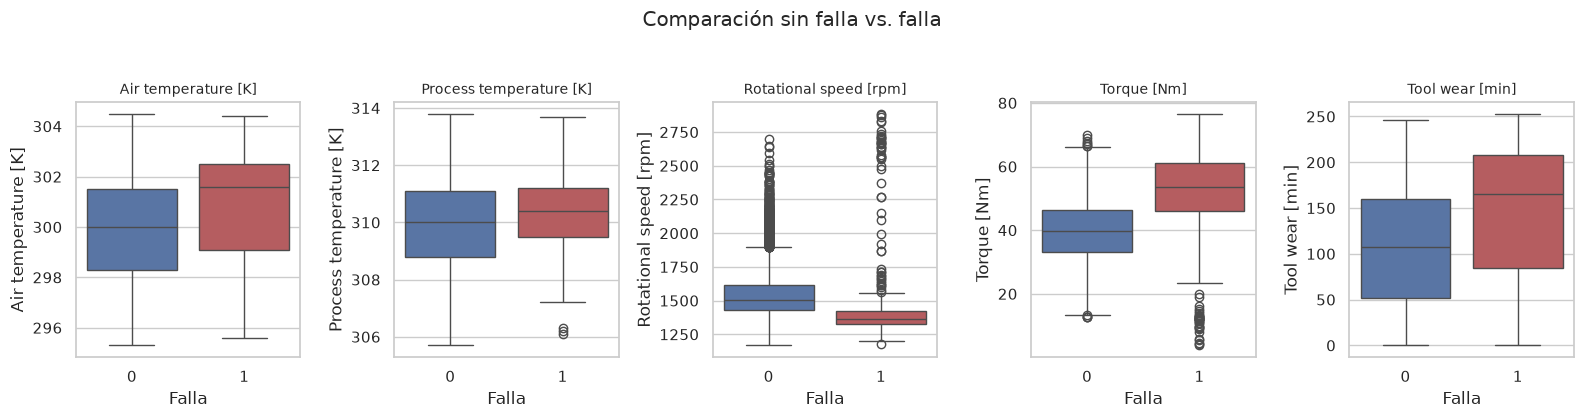

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, config.NUMERIC_COLS):
    sns.boxplot(data=df, x=config.TARGET, y=col, hue=config.TARGET, ax=ax,
                legend=False, palette=["#4c72b0", "#c44e52"])
    ax.set_xlabel("Falla")
    ax.set_title(col, fontsize=10)
plt.suptitle("Comparación sin falla vs. falla", y=1.04)
plt.tight_layout()
plt.show()

Observaciones (asociativas, no causales):

- Los registros con falla presentan en promedio **mayor desgaste** (143.8 vs. 106.7 min)
  y **mayor torque** (50.2 vs. 39.6 Nm).
- Las fallas se concentran en los **extremos operativos** del torque y en la
  temperatura del aire más alta.

## 3. Consultas SQL (SQLite)

In [7]:
import sqlite3

# El pipeline crea la base; si no existe, se crea aquí
if not config.DB_PATH.exists():
    from src.pipeline import build_database
    build_database(df)

with sqlite3.connect(config.DB_PATH) as conn:
    q = pd.read_sql_query('''
        SELECT Type,
               COUNT(*) AS total_registros,
               SUM("Machine failure") AS total_fallas,
               ROUND(100.0 * SUM("Machine failure") / COUNT(*), 2) AS tasa_falla_pct
        FROM observations
        GROUP BY Type ORDER BY Type
    ''', conn)
q

,Type,total_registros,total_fallas,tasa_falla_pct
0,H,1003,21,2.09
1,L,6000,235,3.92
2,M,2997,83,2.77


In [8]:
with sqlite3.connect(config.DB_PATH) as conn:
    q2 = pd.read_sql_query('''
        SELECT CASE
                   WHEN "Torque [Nm]" < 15 THEN 'torque_bajo'
                   WHEN "Torque [Nm]" > 55 THEN 'torque_alto'
                   ELSE 'torque_intermedio'
               END AS banda_torque,
               COUNT(*) AS n_registros,
               SUM("Machine failure") AS n_fallas,
               ROUND(100.0 * SUM("Machine failure") / COUNT(*), 2) AS tasa_falla_pct
        FROM observations
        GROUP BY banda_torque ORDER BY tasa_falla_pct DESC
    ''', conn)
q2

,banda_torque,n_registros,n_fallas,tasa_falla_pct
0,torque_bajo,57,30,52.63
1,torque_alto,608,148,24.34
2,torque_intermedio,9335,161,1.72


Las tasas extremas en `torque_bajo` (52.6%) se basan en un grupo pequeño
(57 registros): por eso el proyecto exige presentar numerador, denominador y
tamaño de grupo en cada consulta (ver `sql/analysis_queries.sql`).

## 4. Modelado: comparación de modelos

In [9]:
report = json.loads(config.METRICS_PATH.read_text(encoding="utf-8"))
rows = []
for name, val in report["validation"].items():
    test = report["test"][name]
    rows.append({
        "Modelo": name,
        "AP (validación)": val["average_precision"],
        "AP (prueba)": test["average_precision"],
        "Precision": test["precision"],
        "Recall": test["recall"],
        "F1": test["f1"],
        "FN": test["confusion_matrix"]["fn"],
        "FP": test["confusion_matrix"]["fp"],
    })
comparativa = pd.DataFrame(rows).set_index("Modelo")
comparativa

,AP (validación),AP (prueba),Precision,Recall,F1,FN,FP
Modelo,,,,,,,
DummyClassifier (prior),0.0340,0.0340,0.0000,0.0000,0.0000,68,0
Regresión logística,0.3680,0.3926,0.1466,0.8235,0.2489,12,326
Random Forest,0.6573,0.6935,0.5795,0.7500,0.6538,17,37


Modelo seleccionado: Random Forest | umbral congelado: 0.54


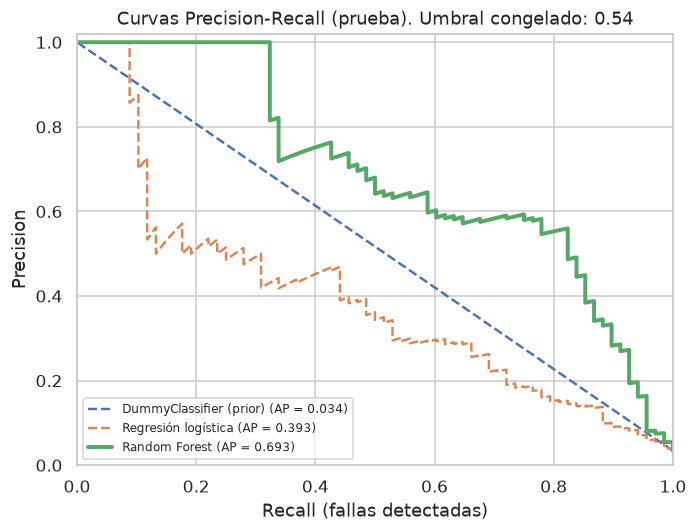

In [10]:
from IPython.display import Image, display

print(f"Modelo seleccionado: {report['selected_model']} | umbral congelado: {report['threshold']}")
display(Image(str(config.FIGURES_DIR / "pr_curves.png"), width=560))

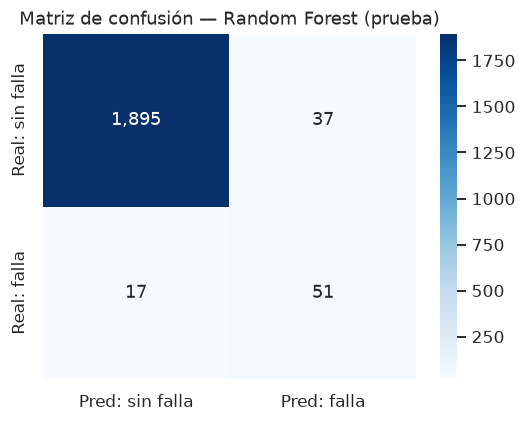

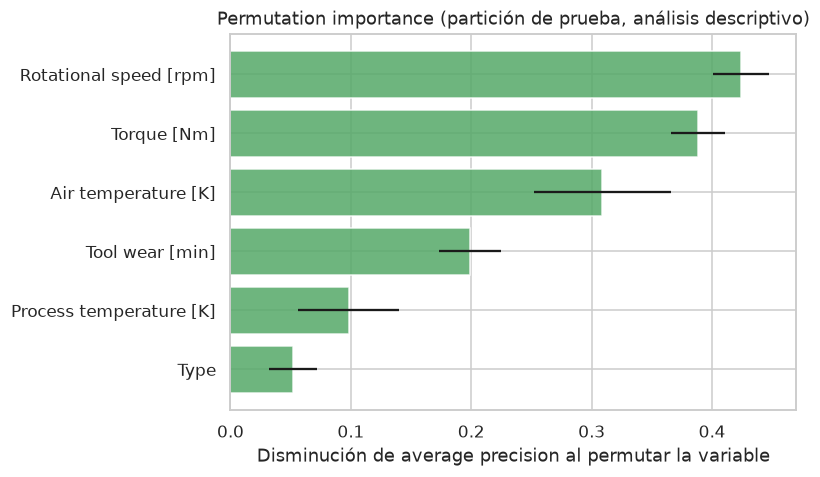

In [11]:
display(Image(str(config.FIGURES_DIR / "confusion_matrix.png"), width=440))
display(Image(str(config.FIGURES_DIR / "permutation_importance.png"), width=640))

## 5. Conclusiones

1. **Desbalance marcado** (3.39% de fallas): el accuracy no es informativo y se usan
   precision, recall, F1 y PR-AUC para la clase minoritaria.
2. **El Random Forest seleccionado** (por average precision en validación) logra en prueba
   F1 0.654 con recall 75.0% y precision 58.0%, frente a la regresión logística
   (recall 82.4% pero precision 14.7% y 326 falsos positivos). El compromiso
   precision-recall depende del costo relativo de falsos negativos vs. falsos positivos.
3. Las variables más asociadas son **velocidad de rotación, torque, temperatura del aire
   y desgaste de herramienta** (permutation importance sobre prueba, análisis descriptivo).

### Limitaciones

- Dataset sintético: no valida desempeño en planta.
- Partición única fija; con 339 fallas, la variabilidad entre semillas es esperable.
- La importancia de variables no implica causalidad.
- El prototipo **no debe usarse como sistema operativo de mantenimiento**.